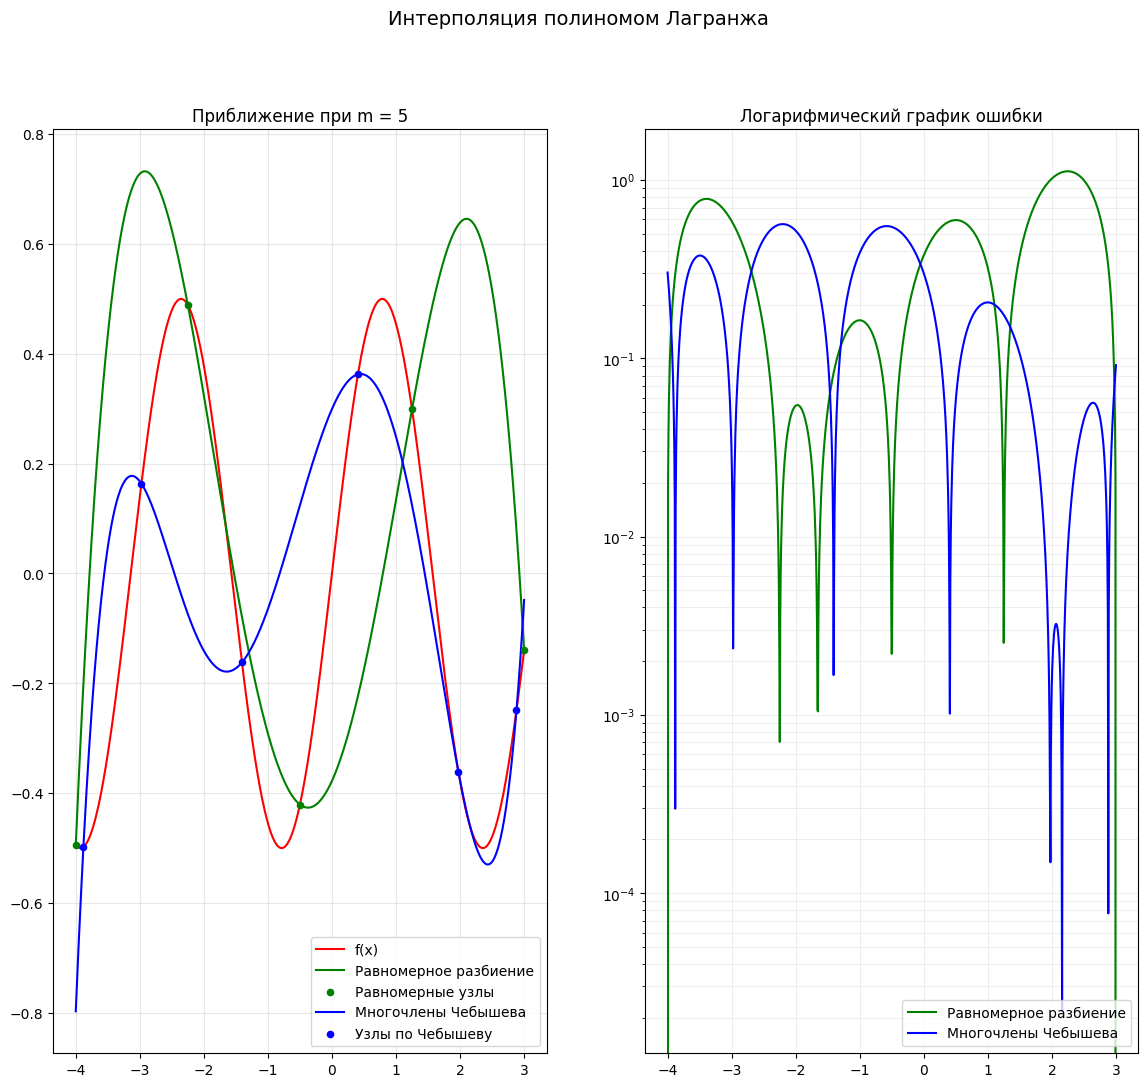

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import math


def f(x):
    return np.sin(x) * (np.cos(x))

def lagrange_interpolation(x_points, y_points, x_eval):
    n = len(x_points)
    res = np.zeros_like(x_eval)
    for i in range(n):
        L_i = np.ones_like(x_eval)
        for j in range(n):
            if i != j:
                L_i *= (x_eval - x_points[j]) / (x_points[i] - x_points[j])
        res += y_points[i] * L_i
    return res


m = 5
a, b = -4, 3
x_fine = np.linspace(a, b, 1000)
y_true = f(x_fine)

fig, axes = plt.subplots(1, 2, figsize=(14, 12))
fig.suptitle("Интерполяция полиномом Лагранжа", fontsize=14)

x_points = np.linspace(a, b, m)
y_points = f(x_points)
y_lagrange = lagrange_interpolation(x_points, y_points, x_fine)
actual_error = np.abs(y_true - y_lagrange)

x_points_chebychev = np.array([(b + a) / 2 + (b - a) / 2 * (-np.cos((2 * i + 1) / (2 * m + 2) * math.pi)) for i in range(m + 1)])
y_points_chebychev = f(x_points_chebychev)
y_lagrange_chebychev = lagrange_interpolation(x_points_chebychev, y_points_chebychev, x_fine)
actual_error_chebychev = np.abs(y_true - y_lagrange_chebychev)

result = {
    "m": m,
    "max_error": np.max(actual_error),
    "max_error_chebychev": np.max(actual_error_chebychev)
}

ax1 = axes[0]
ax1.plot(x_fine, y_true, label="f(x)", color="red")
ax1.plot(x_fine, y_lagrange, label=f"Равномерное разбиение", color="green")
ax1.scatter(x_points, y_points, color="green", s=20, zorder=3, label="Равномерные узлы")
ax1.plot(x_fine, y_lagrange_chebychev, label=f"Многочлены Чебышева", color="blue")
ax1.scatter(x_points_chebychev, y_points_chebychev, color="blue", s=20, zorder=3, label="Узлы по Чебышеву")
ax1.set_title(f"Приближение при m = {m}")
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

ax2 = axes[1]
ax2.semilogy(x_fine, actual_error, label="Равномерное разбиение", color="green")
ax2.semilogy(x_fine, actual_error_chebychev, label="Многочлены Чебышева", color="blue")
ax2.set_title(f"Логарифмический график ошибки")
ax2.legend(loc="lower right")
ax2.grid(True, which="both", ls="-", alpha=0.2)

plt.show()